# Notebook 3 — Regression of the 2nd-semester average grade

We predict the continuous variable `nota_media_2sem` from the student's
characteristics and their 1st-semester performance, avoiding data leakage.

The logic lives in `src/regresion.py`.

## Models

We test models ranging from the simplest to non-linear ones:

- **Simple linear regression** (unregularised) — baseline.
- **Ridge** (L2) — regularises by stabilising the coefficients.
- **Lasso** (L1) — drives coefficients to zero, performing automatic feature
  selection.
- **ElasticNet** (L1+L2) — a combination of both.
- **Linear SVR** — alternative with an `epsilon`-insensitive loss.
- **RBF SVR** — kernel trick, maps to an infinite-dimensional space.
- **Random Forest Regressor** — non-linear, robust to multicollinearity, with
  interpretable `feature_importances`.

## Preprocessing considerations

**Anti data leakage.** The regression dataset was built by removing all
the 2nd-semester variables other than the target. `cargar_datos` checks
this property and aborts if it finds any contaminating column.

**Dropout exclusion.** Students with a 0.0 grade in the 1st or 2nd semester
were also excluded. In this context a 0.0 is not considered low performance but
dropout. Mixing it with real grades would create a bimodal
distribution that no continuous regressor could fit properly.

## 0. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import regresion
from configuracion import (
    REGRESION_TRAIN, REGRESION_TEST,
    DIAGNOSTICO_PREFIX, FEATURE_IMPORTANCE_REG,
    RESUMEN_REGRESION, PREDICCIONES_REGRESION,
    RESULTS_DIR,
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f'Train: {REGRESION_TRAIN}')
print(f'Test: {REGRESION_TEST}')

Train: C:\Users\mb6ja\OneDrive\Documentos\ICAI\2\Machine_Learning\Proyecto_final_Machine_Learning\data\processed\datos_limpios_regresion_train.csv
Test: C:\Users\mb6ja\OneDrive\Documentos\ICAI\2\Machine_Learning\Proyecto_final_Machine_Learning\data\processed\datos_limpios_regresion_test.csv


## 1. Data loading

The `cargar_datos` function aborts if it finds 2nd-semester variables
other than the target among the features, ensuring there is no data leakage.

In [2]:
X_train, y_train, X_test, y_test = regresion.cargar_datos(
    str(REGRESION_TRAIN), str(REGRESION_TEST))

print(f'Train: {X_train.shape[0]} records × {X_train.shape[1]} features')
print(f'Test:  {X_test.shape[0]} records')
print(f'\nTarget nota_media_2sem:')
print(f'  train range: {y_train.min():.2f} to {y_train.max():.2f}')
print(f'  train mean: {y_train.mean():.2f}')
print(f'  train std: {y_train.std():.2f}')
print('\nAnti-leakage check: OK.')

Train: 2750 registros × 29 features
Test:  688 registros

Target nota_media_2sem:
  rango train: 10.00 a 18.57
  media train: 12.78
  std train: 1.39

Comprobación anti-leakage: OK.


### 1.1 Target distribution

We plot the target to understand what we are predicting and later check that the results obtained are reasonable.

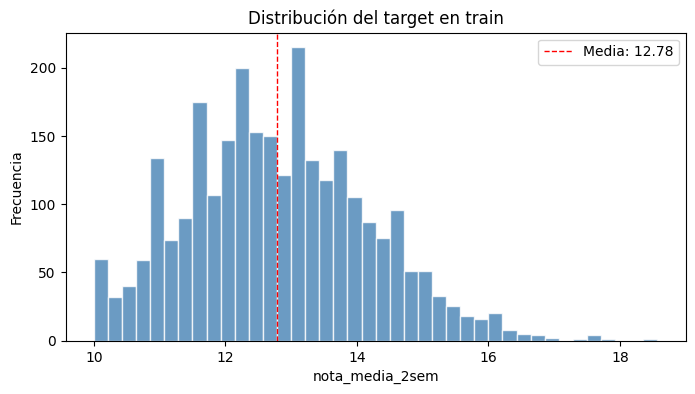

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_train, bins=40, color='steelblue', alpha=0.8, edgecolor='white')
ax.axvline(y_train.mean(), color='red', ls='--', lw=1, label=f'Mean: {y_train.mean():.2f}')
ax.set_xlabel('nota_media_2sem')
ax.set_ylabel('Frequency')
ax.set_title('Target distribution in train')
ax.legend()
plt.show()

Since almost all grades are very similar (they are packed between 10 and 18), it is very hard
for the model to hit the exact number. It is not that every model is bad; with so little
variation in the data, any small miss looks like a huge error. That is why, even if the model is
good, we will never get a perfect $R^2$ score.

## 2. Preprocessor

Same as in classification: `StandardScaler` for numerical variables and `OneHotEncoder` for categorical ones, all inside a
pipeline so that `fit` only sees the training fold in each
CV iteration.

In [4]:
preprocesador = regresion.construir_preprocesador(X_train)
cols_num = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cols_cat = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
print(f'Numerical ({len(cols_num)}): {cols_num}')
print(f'\nCategorical ({len(cols_cat)}): {cols_cat}')

Numéricas (13): ['orden_solicitud', 'nota_cualificacion_previa', 'nota_admision', 'edad_al_matricularse', 'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas', 'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion', 'pib']

Categóricas (16): ['estado_civil', 'modo_solicitud', 'curso', 'asistencia_diurna_vespertina', 'cualificacion_previa', 'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre', 'desplazado', 'necesidades_educativas_especiales', 'deudor', 'matricula_al_dia', 'genero', 'becado', 'internacional']


## 2.5 Baseline (DummyRegressor)

As in classification, before training any model we set a baseline
with a `DummyRegressor`.

We use two strategies:

| Strategy | Prediction |
|---|---|
| `mean` | Always predicts the training mean |
| `median` | Always predicts the training median |

For a model to be considered useful, its RMSE must be below
the baseline RMSE.

In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

estrategias_reg = ['mean', 'median']
filas_baseline_reg = []

for estrategia in estrategias_reg:
    dummy = DummyRegressor(strategy=estrategia)
    dummy.fit(X_train, y_train)
    y_pred_dummy = dummy.predict(X_test)
    r2   = r2_score(y_test, y_pred_dummy)
    rmse = mean_squared_error(y_test, y_pred_dummy) ** 0.5
    mae  = mean_absolute_error(y_test, y_pred_dummy)
    filas_baseline_reg.append({
        'modelo': f'Dummy ({estrategia})',
        'r2_test': r2, 'rmse_test': rmse, 'mae_test': mae})
    print(f"── Dummy strategy='{estrategia}' ──")
    print(f"  R²={r2:.4f}  RMSE={rmse:.4f}  MAE={mae:.4f}")
    print(f"  (always predicts {dummy.constant_.flat[0]:.4f})\n")

df_baseline_reg = pd.DataFrame(filas_baseline_reg)

── Dummy strategy='mean' ──
  R²=-0.0097  RMSE=1.3312  MAE=1.0673
  (predice siempre 12.7822)

── Dummy strategy='median' ──
  R²=-0.0001  RMSE=1.3248  MAE=1.0598
  (predice siempre 12.6667)



## 3. Model and grid definition

In [6]:
modelos = regresion.definir_modelos_y_grids(preprocesador)
for nombre, (_, grid) in modelos.items():
    n_combos = int(np.prod([len(v) for v in grid.values()])) if grid else 1
    print(f'  {nombre:28s}  {n_combos:3d} combinations')

  Regresion_lineal_simple         1 combinaciones
  Ridge                           7 combinaciones
  Lasso                           7 combinaciones
  ElasticNet                     20 combinaciones
  SVR_linear                      9 combinaciones
  SVR_RBF                        36 combinaciones
  RandomForest                   36 combinaciones


## 4. Training with cross-validation

`KFold(5)` with `scoring='r2'`. For each combination 5 models are trained.
RBF SVR is the slowest ($O(n^2)$) and may take a few minutes.

In [7]:
resultados = regresion.entrenar_modelos(modelos, X_train, y_train, verbose=0)


------------------------------------------------------------
  Entrenando: Regresion_lineal_simple
------------------------------------------------------------
Mejor R² (CV):   -8282339948641404928.0000
Mejores params:  {}

------------------------------------------------------------
  Entrenando: Ridge
------------------------------------------------------------
Mejor R² (CV):   0.5051
Mejores params:  {'reg__alpha': 100}

------------------------------------------------------------
  Entrenando: Lasso
------------------------------------------------------------
Mejor R² (CV):   0.5058
Mejores params:  {'reg__alpha': 0.01}

------------------------------------------------------------
  Entrenando: ElasticNet
------------------------------------------------------------
Mejor R² (CV):   0.5078
Mejores params:  {'reg__alpha': 0.01, 'reg__l1_ratio': 0.7}

------------------------------------------------------------
  Entrenando: SVR_linear
------------------------------------------------

## 5. Test evaluation

Reported metrics:

- **R²**: proportion of explained variance (0 = constant model, 1 = perfect).
- **RMSE**: root mean squared error, penalises large errors.
- **MAE**: mean absolute error, more directly interpretable on the grade
  scale.

In [8]:
df_resumen = regresion.evaluar_en_test(resultados, X_test, y_test, path_resumen_csv=str(RESUMEN_REGRESION))

 Regresion_lineal_simple    R²=0.4914  RMSE=0.9447  MAE=0.7320
 Ridge                      R²=0.5029  RMSE=0.9340  MAE=0.7211
 Lasso                      R²=0.4997  RMSE=0.9370  MAE=0.7208
 ElasticNet                 R²=0.5019  RMSE=0.9349  MAE=0.7195
 SVR_linear                 R²=0.4957  RMSE=0.9408  MAE=0.7239
 SVR_RBF                    R²=0.5019  RMSE=0.9349  MAE=0.7199
 RandomForest               R²=0.5291  RMSE=0.9091  MAE=0.6945

------------------------------------------------------------
  RESUMEN COMPARATIVO (ordenado por R² en test)
------------------------------------------------------------
                 modelo         r2_cv  r2_test  rmse_test  mae_test                                                               mejores_params
           RandomForest  5.226150e-01 0.529086   0.909074  0.694483 {'reg__max_depth': 10, 'reg__min_samples_leaf': 1, 'reg__n_estimators': 300}
                  Ridge  5.050930e-01 0.502941   0.933969  0.721115                               

### 5.1 Comparison table

In [9]:
# Unified table: real models + baseline
df_comparacion_reg = pd.concat([
    df_resumen[['modelo', 'r2_test', 'rmse_test', 'mae_test']],
    df_baseline_reg,
], ignore_index=True).sort_values('r2_test', ascending=False)

rmse_baseline = df_baseline_reg.loc[df_baseline_reg['modelo'] == 'Dummy (mean)', 'rmse_test'].values[0]
df_comparacion_reg['reduccion_rmse_vs_mean'] = (
    (rmse_baseline - df_comparacion_reg['rmse_test']) / rmse_baseline * 100
).map(lambda x: f'{x:+.1f}%')

df_comparacion_reg.reset_index(drop=True)

,modelo,r2_test,rmse_test,mae_test,reduccion_rmse_vs_mean
0,RandomForest,0.529086,0.909074,0.694483,+31.7%
1,Ridge,0.502941,0.933969,0.721115,+29.8%
2,SVR_RBF,0.501935,0.934914,0.719923,+29.8%
3,ElasticNet,0.501919,0.934929,0.719466,+29.8%
4,Lasso,0.499689,0.937019,0.720753,+29.6%
5,SVR_linear,0.495665,0.940780,0.723949,+29.3%
6,Regresion_lineal_simple,0.491436,0.944716,0.732043,+29.0%
7,Dummy (median),-0.000129,1.324819,1.059836,+0.5%
8,Dummy (mean),-0.009718,1.331155,1.067265,+0.0%


In [10]:
df_resumen[['modelo', 'r2_cv', 'r2_test', 'rmse_test', 'mae_test']]

,modelo,r2_cv,r2_test,rmse_test,mae_test
0,RandomForest,5.226150e-01,0.529086,0.909074,0.694483
1,Ridge,5.050930e-01,0.502941,0.933969,0.721115
2,SVR_RBF,5.347384e-01,0.501935,0.934914,0.719923
3,ElasticNet,5.077927e-01,0.501919,0.934929,0.719466
4,Lasso,5.058474e-01,0.499689,0.937019,0.720753
5,SVR_linear,5.011051e-01,0.495665,0.940780,0.723949
6,Regresion_lineal_simple,-8.282340e+18,0.491436,0.944716,0.732043


### 5.2 Comparative interpretation


- If simple linear regression, Ridge and RBF SVR perform similarly, the
  `target - features` relationship is linear: there are no non-linearities for the kernel to exploit.
- If Lasso matches or beats Ridge with many coefficients at zero, there is
  high redundancy between variables (consistent with the multicollinearity
  among the 1st-semester variables).
- If Random Forest clearly wins, there is relevant non-linear structure.

## 6. Graphical diagnostics of the best model

For the model with the highest test R², we plot:

- **Predicted vs actual**: ideally the points fall on the diagonal.
- **Residuals vs predicted**: ideally a structureless cloud around 0.
  Any pattern (curvature, funnel, bands) indicates that the model is
  missing signal.

Mejor modelo en test: RandomForest


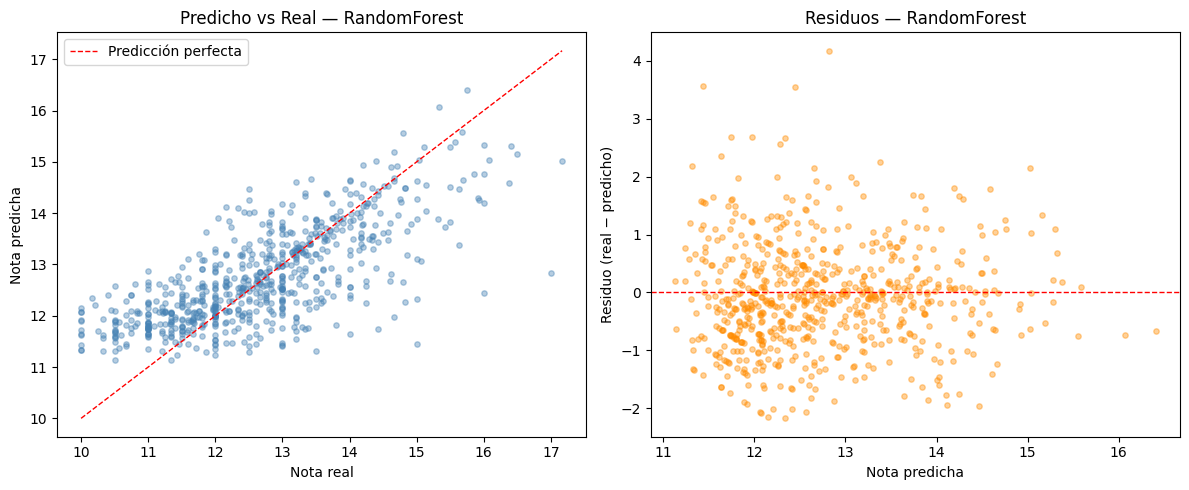

In [11]:
nombre_mejor = df_resumen.iloc[0]['modelo']
print(f'Best model on test: {nombre_mejor}')

fig_diag = regresion.diagnostico_grafico(
    nombre_mejor, resultados[nombre_mejor], X_test, y_test,
    path_fig=str(DIAGNOSTICO_PREFIX) + f'{nombre_mejor}.png')
plt.show()

**Reading:**

- The residuals form a uniform cloud with no apparent pattern,
  so we are looking at homoscedasticity, which is exactly what we want.

With a linear model (Ridge, Lasso) these patterns are usually less pronounced
because there is no averaging.

### 6.1 Lasso diagnostics for comparison

It is worth comparing the diagnostics of the non-linear model (the best fit for this problem) with those of a
linear model to see the effect of shrinkage.

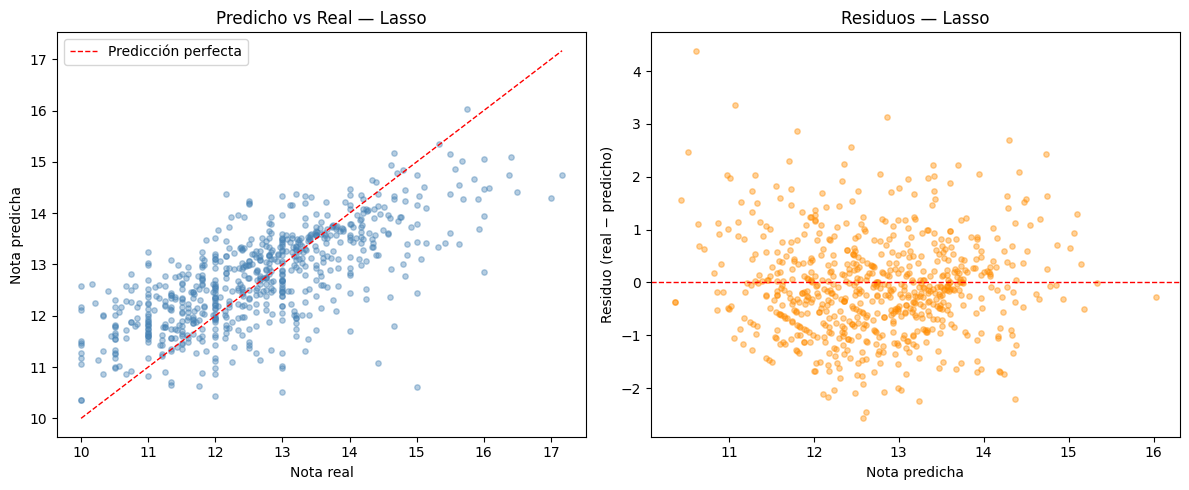

In [12]:
if 'Lasso' in resultados and nombre_mejor != 'Lasso':
    fig_lasso = regresion.diagnostico_grafico(
        'Lasso', resultados['Lasso'], X_test, y_test,
        path_fig=str(DIAGNOSTICO_PREFIX) + 'Lasso.png',
    )
    plt.show()

## 7. Interpretability

### 7.1 Lasso coefficients

Lasso drives coefficients to zero, which provides an automatic selection of
the most informative variables. The sign indicates the direction of the effect,
interpretable on already standardised variables.

In [13]:
df_coefs = regresion.coeficientes_lasso(resultados['Lasso'], top_n=15)
df_coefs


  Lasso: 21 / 109 variables con coef != 0


,variable,coeficiente
0,nota_media_1sem,0.760386
1,asignaturas_1sem_aprobadas,0.215114
2,curso_enfermeria,0.212362
3,curso_diseno_de_comunicacion,-0.182519
4,curso_educacion_basica,-0.178904
5,asignaturas_1sem_evaluadas,-0.178329
6,deudor_no,0.082162
7,nota_admision,0.074853
8,curso_gestion_de_publicidad_y_marketing,0.073775
9,tasa_desempleo,0.069624


### 7.2 Random Forest feature importance

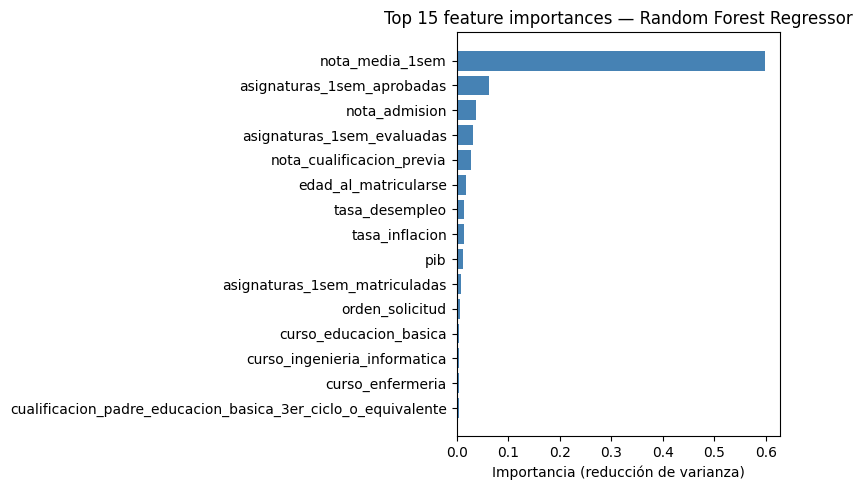

,variable,importancia
0,nota_media_1sem,0.597279
1,asignaturas_1sem_aprobadas,0.062670
2,nota_admision,0.038509
3,asignaturas_1sem_evaluadas,0.031708
4,nota_cualificacion_previa,0.028845
5,edad_al_matricularse,0.019093
6,tasa_desempleo,0.014198
7,tasa_inflacion,0.014099
8,pib,0.013076
9,asignaturas_1sem_matriculadas,0.008376


In [14]:
df_imp, fig_imp = regresion.importancia_rf(
    resultados['RandomForest'],
    top_n=15,
    path_fig=str(FEATURE_IMPORTANCE_REG))

plt.show()
df_imp

### 7.3 Interpretation

**Dominant variable:** `nota_media_1sem`. This is expected, since academic performance tends to be consistent from one semester to the next.

**A note on Gini importance.** In the presence of high
multicollinearity (e.g. between `asignaturas_1sem_aprobadas` and `nota_media_1sem`, which
are strongly correlated), the RF finds that one of them summarises the information and the
others end up with low importance, not because they are uninformative but
because they are redundant (they explain the same thing).

**Lasso and RF agreement.** If the top variables of both lists match, we have robust evidence of their relevance.
If they differ, the RF is probably capturing non-linear effects or
interactions between variables that Lasso has not captured.

## 8. Saving the best model's predictions

In [15]:
preds = pd.DataFrame({
    'y_real': y_test.values,
    'y_pred': resultados[nombre_mejor].predict(X_test)})

preds.to_csv(PREDICCIONES_REGRESION, index=False)
print(f'Saved: {PREDICCIONES_REGRESION}')
preds.head()

Guardado: C:\Users\mb6ja\OneDrive\Documentos\ICAI\2\Machine_Learning\Proyecto_final_Machine_Learning\results\predicciones_regresion.csv


,y_real,y_pred
0,12.714286,12.574854
1,14.333333,13.482271
2,11.250000,11.837533
3,11.832000,12.213198
4,10.333333,11.620697


## 9. Conclusions

- The R² obtained is relatively low because we are trying to predict an
  individual grade using only prior
  information. This is consistent with the target having a
  small standard deviation (1.4) within a narrow range.
- The dominant predictor is **1st-semester performance**. The regularised
  linear models and the RF agree on this conclusion.
- Tree-based models are expected to show **shrinkage** towards the target
  mean: they underestimate the best students and
  overestimate the weakest ones.